In [1]:
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy.stats import norm
con = duckdb.connect("../../spectrum.duckdb")
def q(sql): return con.execute(sql).df()

In [2]:
q("SELECT * FROM customers_clean").to_csv("../outputs/customers_clean.csv", index=False)

q("""SELECT DATE_TRUNC('month', churn_date) AS month, COUNT(*) AS disconnects
     FROM customers_clean WHERE churned
     GROUP BY 1 ORDER BY 1""").to_csv("../outputs/monthly_churn.csv", index=False)

q("""SELECT churn_reason, COUNT(*) AS customers
     FROM customers_clean WHERE churned
     GROUP BY 1 ORDER BY 2 DESC""").to_csv("../outputs/churn_reasons.csv", index=False)

print("Saved!")

Saved!


In [3]:
off = q("SELECT * FROM retention_offers")
s = off.groupby("test_group").agg(customers=("customer_id", "count"),
                                   churned=("churned_within_90d", "sum"),
                                   cost=("offer_cost_monthly", "max"))
s["churn_rate"] = s.churned / s.customers
s.sort_values("churn_rate")

,customers,churned,cost,churn_rate
test_group,,,,
Mobile Line Free 1yr,999,157,14,0.157157
Discount $10x12mo,981,156,10,0.159021
Free Speed Upgrade,1032,172,6,0.166667
Control,988,200,0,0.202429


In [4]:
ctl = s.loc["Control"]
rows = []
for offer, r in s.drop("Control").iterrows():
    p_pool = (r.churned + ctl.churned) / (r.customers + ctl.customers)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / r.customers + 1 / ctl.customers))
    p_value = norm.cdf((r.churn_rate - ctl.churn_rate) / se)
    saves = (ctl.churn_rate - r.churn_rate) * r.customers
    annual_cost = r.cost * 12 * (r.customers - r.churned)
    rows.append([offer, round(r.churn_rate * 100, 1), round(p_value, 4),
                 round(saves), round(annual_cost / saves)])

result = pd.DataFrame(rows, columns=["offer", "churn_90d_pct", "p_value", "saves", "cost_per_save"])
result.to_csv("../outputs/offer_test_results.csv", index=False)
result

,offer,churn_90d_pct,p_value,saves,cost_per_save
0,Discount $10x12mo,15.9,0.0062,43,2325
1,Free Speed Upgrade,16.7,0.0191,37,1678
2,Mobile Line Free 1yr,15.7,0.0043,45,3128


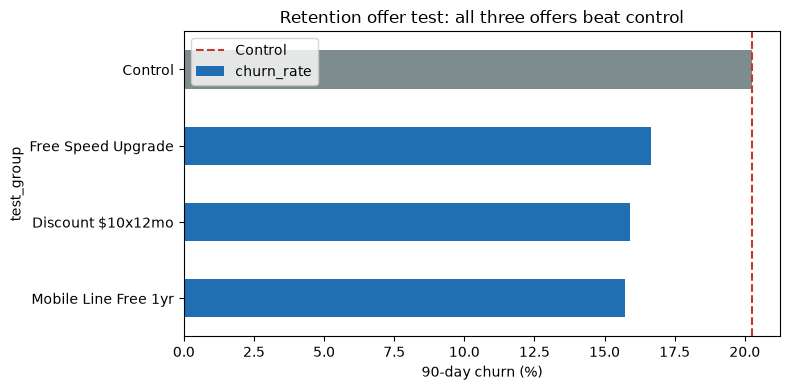

In [5]:
plot = s.sort_values("churn_rate")
colors = ["#7f8c8d" if g == "Control" else "#1f6fb2" for g in plot.index]
ax = (plot.churn_rate * 100).plot.barh(color=colors, figsize=(8, 4))
ax.axvline(ctl.churn_rate * 100, color="#c0392b", linestyle="--", label="Control")
ax.set_xlabel("90-day churn (%)")
ax.set_title("Retention offer test: all three offers beat control")
ax.legend()
ax.figure.tight_layout()
ax.figure.savefig("../images/offer_test.png", dpi=150)


In [7]:
con.close()